In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor


df = pd.read_csv(
    r"C:\Users\User\OneDrive - Kaunas University of Technology\Desktop\ML\LAB1\quebec_housing_sales_v2.csv"
)

print("Dataset shape:", df.shape)
display(df.head())
print(df.isnull().sum())

Dataset shape: (5000, 14)


,property_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
0,1,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,NaN,Yes,No,2024,326000
1,2,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000
2,3,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,NaN,Yes,Yes,2025,273000
3,4,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000
4,5,Longueuil,Greenfield Park,Condo,2,2,714,NaN,1997,2010.0,Yes,No,2022,371000


property_id            0
city                   0
neighborhood           0
property_type          0
bedrooms               0
bathrooms              0
living_area_sqft       0
lot_size_sqft       1211
year_built             0
renovation_year     3408
garage                 0
basement               0
sale_year              0
sale_price             0
dtype: int64


In [6]:
# Remove identifier
df = df.drop(columns=["property_id"], errors="ignore")

# Separate features and target
X = df.drop(columns=["sale_price"])
y = df["sale_price"]

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Identify numerical and categorical features
numeric_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols = X_train.select_dtypes(exclude=np.number).columns

# Fill missing values using training statistics only
for col in numeric_cols:
    median = X_train[col].median()

    X_train[col] = X_train[col].fillna(median)
    X_val[col] = X_val[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

for col in categorical_cols:
    X_train[col] = X_train[col].fillna("Unknown")
    X_val[col] = X_val[col].fillna("Unknown")
    X_test[col] = X_test[col].fillna("Unknown")

# Reset indexes
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (3500, 12)
Validation: (750, 12)
Testing: (750, 12)


In [7]:
class RegressionTree:
    def __init__(self, max_depth=5, min_samples_split=10,
                 min_samples_leaf=5):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def mse(self, y):
        return np.mean((y - np.mean(y)) ** 2)

    def best_split(self, X, y):
        best_error = self.mse(y)
        best = None

        for feature in X.columns:
            values = X[feature]

            if pd.api.types.is_numeric_dtype(values):
                unique = np.sort(values.unique())

                if len(unique) <= 1:
                    continue

                if len(unique) == 2:
                    thresholds = [unique[0]]
                else:
                    thresholds = np.quantile(
                        unique, np.linspace(0.1, 0.9, 5)
                    )

                for threshold in np.unique(thresholds):
                    left = values <= threshold
                    right = ~left

                    if min(left.sum(), right.sum()) < self.min_samples_leaf:
                        continue

                    error = (
                        left.mean() * self.mse(y[left]) +
                        right.mean() * self.mse(y[right])
                    )

                    if error < best_error:
                        best_error = error
                        best = (feature, "numeric", threshold)

            else:
                categories = values.unique()

                if len(categories) < 2:
                    continue

                groups = [values == c for c in categories]

                if any(g.sum() < self.min_samples_leaf for g in groups):
                    continue

                error = sum(
                    g.mean() * self.mse(y[g])
                    for g in groups
                )

                if error < best_error:
                    best_error = error
                    best = (feature, "categorical", categories)

        return best

    def build(self, X, y, depth=0):
        node = {"prediction": float(y.mean())}

        if (
            depth >= self.max_depth or
            len(y) < self.min_samples_split or
            len(y) < 2 * self.min_samples_leaf or
            self.mse(y) == 0
        ):
            return node

        split = self.best_split(X, y)

        if split is None:
            return node

        feature, kind, value = split

        node["feature"] = feature
        node["kind"] = kind

        if kind == "numeric":
            node["threshold"] = float(value)

            mask = X[feature] <= value

            node["left"] = self.build(
                X[mask], y[mask], depth + 1
            )
            node["right"] = self.build(
                X[~mask], y[~mask], depth + 1
            )

        else:
            node["branches"] = {}

            for category in value:
                mask = X[feature] == category
                node["branches"][category] = self.build(
                    X[mask], y[mask], depth + 1
                )

        return node

    def fit(self, X, y):
        self.tree = self.build(X, y)
        return self

    def predict_one(self, row, node):
        if "feature" not in node:
            return node["prediction"]

        feature = node["feature"]

        if node["kind"] == "numeric":
            if row[feature] <= node["threshold"]:
                return self.predict_one(row, node["left"])
            return self.predict_one(row, node["right"])

        branch = node["branches"].get(row[feature])

        if branch is None:
            return node["prediction"]

        return self.predict_one(row, branch)

    def predict(self, X):
        return np.array([
            self.predict_one(row, self.tree)
            for _, row in X.iterrows()
        ])


# Train one example tree
tree = RegressionTree(max_depth=5)
tree.fit(X_train, y_train)

predictions = tree.predict(X_val)

print("Validation MAE:", mean_absolute_error(y_val, predictions))
print("Validation MSE:", mean_squared_error(y_val, predictions))

Validation MAE: 78101.9347630295
Validation MSE: 10319302953.531008


In [8]:
# Five combinations of tree hyperparameters
parameters = [
    (3, 10, 5),
    (5, 10, 5),
    (7, 10, 5),
    (5, 20, 10),
    (7, 20, 10)
]

regression_results = []
best_mae = float("inf")
best_regression_tree = None
best_regression_params = None

for depth, min_split, min_leaf in parameters:

    model = RegressionTree(
        max_depth=depth,
        min_samples_split=min_split,
        min_samples_leaf=min_leaf
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mae = mean_absolute_error(y_train, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)

    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_mape = np.mean(
        np.abs((y_train - train_pred) / y_train)
    ) * 100

    val_mape = np.mean(
        np.abs((y_val - val_pred) / y_val)
    ) * 100

    regression_results.append({
        "Max Depth": depth,
        "Min Split": min_split,
        "Min Leaf": min_leaf,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Train MSE": train_mse,
        "Validation MSE": val_mse,
        "Train MAPE (%)": train_mape,
        "Validation MAPE (%)": val_mape
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_regression_tree = model
        best_regression_params = (depth, min_split, min_leaf)

regression_df = pd.DataFrame(regression_results)

display(regression_df.round(2))

print("Best parameters:", best_regression_params)
print("Best validation MAE:", round(best_mae, 2))

,Max Depth,Min Split,Min Leaf,Train MAE,Validation MAE,Train MSE,Validation MSE,Train MAPE (%),Validation MAPE (%)
0,3,10,5,80328.06,81497.34,1.097847e+10,1.062706e+10,18.76,19.00
1,5,10,5,69157.04,78101.93,8.583374e+09,1.031930e+10,16.35,18.31
2,7,10,5,62338.85,80539.55,7.080314e+09,1.129414e+10,14.75,18.80
3,5,20,10,94555.00,99183.55,1.423810e+10,1.504806e+10,22.45,23.34
4,7,20,10,89483.16,101641.09,1.304519e+10,1.579142e+10,21.18,23.98


Best parameters: (5, 10, 5)
Best validation MAE: 78101.93


In [9]:
sklearn_results = []

# Convert categorical features for scikit-learn
X_train_sk = pd.get_dummies(X_train)
X_val_sk = pd.get_dummies(X_val)

X_val_sk = X_val_sk.reindex(
    columns=X_train_sk.columns,
    fill_value=0
)

for depth, min_split, min_leaf in parameters:

    model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_split=min_split,
        min_samples_leaf=min_leaf,
        random_state=42
    )

    model.fit(X_train_sk, y_train)

    train_pred = model.predict(X_train_sk)
    val_pred = model.predict(X_val_sk)

    sklearn_results.append({
        "Max Depth": depth,
        "Min Split": min_split,
        "Min Leaf": min_leaf,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred),
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Validation MSE": mean_squared_error(y_val, val_pred),
        "Train MAPE (%)": np.mean(
            np.abs((y_train - train_pred) / y_train)
        ) * 100,
        "Validation MAPE (%)": np.mean(
            np.abs((y_val - val_pred) / y_val)
        ) * 100
    })

sklearn_df = pd.DataFrame(sklearn_results)

display(sklearn_df.round(2))

print("Best sklearn model:")
display(
    sklearn_df.loc[
        sklearn_df["Validation MAE"].idxmin()
    ]
)

,Max Depth,Min Split,Min Leaf,Train MAE,Validation MAE,Train MSE,Validation MSE,Train MAPE (%),Validation MAPE (%)
0,3,10,5,103037.84,104265.32,1.692019e+10,1.668572e+10,24.54,24.49
1,5,10,5,90242.28,93853.30,1.363143e+10,1.401300e+10,21.60,22.20
2,7,10,5,77630.01,84709.17,1.064957e+10,1.189450e+10,18.58,20.01
3,5,20,10,90370.02,94777.09,1.362903e+10,1.406188e+10,21.72,22.37
4,7,20,10,79630.55,86524.61,1.114033e+10,1.246481e+10,19.16,20.34


Best sklearn model:


Max Depth              7.000000e+00
Min Split              1.000000e+01
Min Leaf               5.000000e+00
Train MAE              7.763001e+04
Validation MAE         8.470917e+04
Train MSE              1.064957e+10
Validation MSE         1.189450e+10
Train MAPE (%)         1.857542e+01
Validation MAPE (%)    2.000805e+01
Name: 2, dtype: float64

In [10]:
def print_tree(node, depth=0, max_levels=3):
    if depth >= max_levels:
        return

    indent = "    " * depth

    if "feature" not in node:
        print(indent + f"Predict: {node['prediction']:.2f}")
        return

    feature = node["feature"]

    if node["kind"] == "numeric":
        threshold = node["threshold"]

        print(indent + f"{feature} <= {threshold:.2f}")

        print_tree(node["left"], depth + 1, max_levels)

        print(indent + f"{feature} > {threshold:.2f}")

        print_tree(node["right"], depth + 1, max_levels)

    else:
        print(indent + f"Split by {feature}")

        for category, branch in node["branches"].items():
            print(indent + f"  Category: {category}")
            print_tree(branch, depth + 1, max_levels)


print("Best regression tree:")
print_tree(best_regression_tree.tree)

Best regression tree:
Split by property_type
  Category: Single Family
    Split by city
      Category: Trois-Rivières
        living_area_sqft <= 1536.00
        living_area_sqft > 1536.00
      Category: Saint-Jérôme
        living_area_sqft <= 1293.90
        living_area_sqft > 1293.90
      Category: Gatineau
        living_area_sqft <= 1334.50
        living_area_sqft > 1334.50
      Category: Brossard
        living_area_sqft <= 1669.60
        living_area_sqft > 1669.60
      Category: Montréal
        sale_year <= 2023.00
        sale_year > 2023.00
      Category: Mirabel
        sale_year <= 2022.20
        sale_year > 2022.20
      Category: Longueuil
        sale_year <= 2024.60
        sale_year > 2024.60
      Category: Candiac
        living_area_sqft <= 1471.00
        living_area_sqft > 1471.00
      Category: Sherbrooke
        living_area_sqft <= 1329.40
        living_area_sqft > 1329.40
      Category: Laval
        sale_year <= 2023.00
        sale_year > 2023.00

In [11]:
# Five price categories based on training data
price_thresholds = np.quantile(
    y_train, [0.2, 0.4, 0.6, 0.8]
)

class_names = [
    "Very Low",
    "Low",
    "Medium",
    "High",
    "Very High"
]

def price_to_class(y):
    return np.searchsorted(
        price_thresholds, np.asarray(y), side="right"
    )

y_train_class = pd.Series(price_to_class(y_train))
y_val_class = pd.Series(price_to_class(y_val))

print("Price thresholds:", price_thresholds)
print("\nTraining class distribution:")
print(y_train_class.value_counts().sort_index())

display(pd.DataFrame({
    "Class": range(5),
    "Name": class_names
}))

Price thresholds: [333000. 412600. 499000. 617200.]

Training class distribution:
0    698
1    702
2    696
3    704
4    700
Name: count, dtype: int64


,Class,Name
0,0,Very Low
1,1,Low
2,2,Medium
3,3,High
4,4,Very High


In [12]:
class ClassificationTree(RegressionTree):

    def gini(self, y):
        probabilities = np.bincount(
            np.asarray(y, dtype=int), minlength=5
        ) / len(y)

        return 1 - np.sum(probabilities ** 2)

    def mse(self, y):
        # Override the regression split criterion
        return self.gini(y)

    def build(self, X, y, depth=0):
        # Store majority class instead of mean price
        counts = np.bincount(
            np.asarray(y, dtype=int), minlength=5
        )
        node = {"prediction": int(np.argmax(counts))}

        if (
            depth >= self.max_depth or
            len(y) < self.min_samples_split or
            len(y) < 2 * self.min_samples_leaf or
            self.gini(y) == 0
        ):
            return node

        split = self.best_split(X, y)

        if split is None:
            return node

        feature, kind, value = split

        node["feature"] = feature
        node["kind"] = kind

        if kind == "numeric":
            node["threshold"] = float(value)
            mask = X[feature] <= value

            node["left"] = self.build(
                X[mask], y[mask], depth + 1
            )
            node["right"] = self.build(
                X[~mask], y[~mask], depth + 1
            )

        else:
            node["branches"] = {}

            for category in value:
                mask = X[feature] == category

                node["branches"][category] = self.build(
                    X[mask], y[mask], depth + 1
                )

        return node

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(
        y_true, y_pred, labels=range(5)
    )

    specificities = []

    for i in range(5):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        specificity = tn / (tn + fp) if tn + fp else 0
        specificities.append(specificity)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            average="macro", zero_division=0
        ),
        "Specificity": np.mean(specificities)
    }


classification_results = []
best_class_accuracy = -1
best_class_tree = None
best_class_params = None

for depth, min_split, min_leaf in parameters:

    model = ClassificationTree(
        max_depth=depth,
        min_samples_split=min_split,
        min_samples_leaf=min_leaf
    )

    model.fit(X_train, y_train_class)

    train_pred = model.predict(X_train).astype(int)
    val_pred = model.predict(X_val).astype(int)

    train_metrics = classification_metrics(
        y_train_class, train_pred
    )
    val_metrics = classification_metrics(
        y_val_class, val_pred
    )

    classification_results.append({
        "Max Depth": depth,
        "Min Split": min_split,
        "Min Leaf": min_leaf,
        **{"Train " + k: v for k, v in train_metrics.items()},
        **{"Validation " + k: v for k, v in val_metrics.items()}
    })

    if val_metrics["Accuracy"] > best_class_accuracy:
        best_class_accuracy = val_metrics["Accuracy"]
        best_class_tree = model
        best_class_params = (depth, min_split, min_leaf)

classification_df = pd.DataFrame(classification_results)

display(classification_df.round(4))

print("Best parameters:", best_class_params)
print("Best validation accuracy:", best_class_accuracy)

,Max Depth,Min Split,Min Leaf,Train Accuracy,Train Precision,Train Recall,Train Specificity,Validation Accuracy,Validation Precision,Validation Recall,Validation Specificity
0,3,10,5,0.6297,0.6345,0.6297,0.9074,0.4920,0.4942,0.4894,0.8734
1,5,10,5,0.7031,0.7036,0.7032,0.9258,0.5027,0.4953,0.4984,0.8758
2,7,10,5,0.7123,0.7129,0.7123,0.9281,0.5160,0.5102,0.5123,0.8792
3,5,20,10,0.6017,0.6026,0.6017,0.9004,0.4893,0.4826,0.4859,0.8725
4,7,20,10,0.6023,0.6026,0.6023,0.9006,0.4907,0.4835,0.4872,0.8729


Best parameters: (7, 10, 5)
Best validation accuracy: 0.516


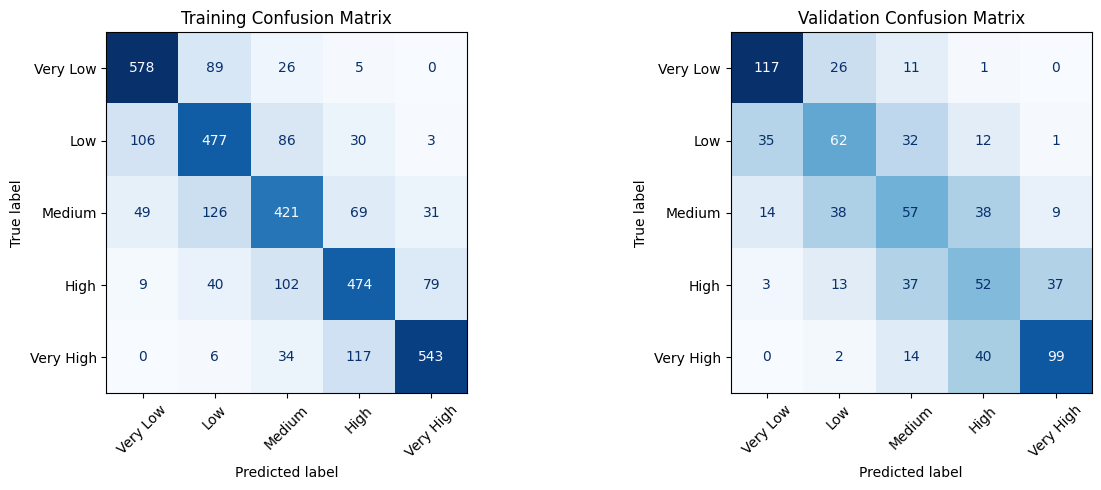

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, X_data, y_data, title in [
    (axes[0], X_train, y_train_class, "Training"),
    (axes[1], X_val, y_val_class, "Validation")
]:
    predictions = best_class_tree.predict(X_data).astype(int)

    cm = confusion_matrix(
        y_data, predictions, labels=range(5)
    )

    ConfusionMatrixDisplay(
        cm, display_labels=class_names
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

    ax.set_title(title + " Confusion Matrix")

plt.tight_layout()
plt.savefig("classification_confusion_matrices.png", dpi=200)
plt.show()

In [15]:
sklearn_class_results = []

for depth, min_split, min_leaf in parameters:

    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=min_split,
        min_samples_leaf=min_leaf,
        criterion="gini",
        random_state=42
    )

    model.fit(X_train_sk, y_train_class)

    train_pred = model.predict(X_train_sk)
    val_pred = model.predict(X_val_sk)

    train_metrics = classification_metrics(
        y_train_class, train_pred
    )
    val_metrics = classification_metrics(
        y_val_class, val_pred
    )

    sklearn_class_results.append({
        "Max Depth": depth,
        "Min Split": min_split,
        "Min Leaf": min_leaf,
        **{"Train " + k: v for k, v in train_metrics.items()},
        **{"Validation " + k: v for k, v in val_metrics.items()}
    })

sklearn_class_df = pd.DataFrame(sklearn_class_results)

display(sklearn_class_df.round(4))

,Max Depth,Min Split,Min Leaf,Train Accuracy,Train Precision,Train Recall,Train Specificity,Validation Accuracy,Validation Precision,Validation Recall,Validation Specificity
0,3,10,5,0.4083,0.4363,0.4078,0.8520,0.3800,0.3456,0.3817,0.8458
1,5,10,5,0.4854,0.4886,0.4854,0.8714,0.4653,0.4470,0.4601,0.8662
2,7,10,5,0.5446,0.5371,0.5447,0.8861,0.5013,0.4814,0.4963,0.8753
3,5,20,10,0.4854,0.4906,0.4854,0.8714,0.4627,0.4409,0.4573,0.8655
4,7,20,10,0.5389,0.5339,0.5389,0.8847,0.5200,0.5047,0.5161,0.8801


In [16]:
def print_tree_compact(node, depth=0, max_depth=3, max_branches=3):
    if depth >= max_depth:
        return

    indent = "  " * depth

    if "feature" not in node:
        print(indent + f"Predict class {node['prediction']}")
        return

    feature = node["feature"]

    if node["kind"] == "numeric":
        print(indent + f"{feature} <= {node['threshold']:.2f}")
        print_tree_compact(
            node["left"], depth + 1, max_depth, max_branches
        )

        print(indent + f"{feature} > {node['threshold']:.2f}")
        print_tree_compact(
            node["right"], depth + 1, max_depth, max_branches
        )

    else:
        print(indent + f"Split by {feature}")

        branches = list(node["branches"].items())

        for category, branch in branches[:max_branches]:
            print(indent + f"Category: {category}")
            print_tree_compact(
                branch, depth + 1, max_depth, max_branches
            )

        if len(branches) > max_branches:
            print(indent + f"... {len(branches)-max_branches} more branches")


print("Best classification tree:")
print_tree_compact(best_class_tree.tree)

Best classification tree:
Split by neighborhood
Category: Trois-Rivières-Ouest
  living_area_sqft <= 1282.00
    sale_year <= 2024.60
    sale_year > 2024.60
  living_area_sqft > 1282.00
    Split by garage
    Category: Yes
    Category: No
Category: West Island
  living_area_sqft <= 1304.00
    bedrooms <= 3.50
    bedrooms > 3.50
  living_area_sqft > 1304.00
    sale_year <= 2021.40
    sale_year > 2021.40
Category: Bellefeuille
  living_area_sqft <= 1276.00
    living_area_sqft <= 1015.00
    living_area_sqft > 1015.00
  living_area_sqft > 1276.00
    sale_year <= 2021.60
    sale_year > 2021.60
... 69 more branches


In [17]:
class RandomForest:
    def __init__(self, n_trees=10, max_depth=5,
                 min_samples_leaf=5, random_state=42):

        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        rng = np.random.default_rng(self.random_state)

        n_samples = len(X)
        n_features = max(1, int(np.sqrt(X.shape[1])))

        for i in range(self.n_trees):

            # Bootstrap sample
            indices = rng.choice(
                n_samples, size=n_samples, replace=True
            )

            # Random subset of features
            features = rng.choice(
                X.columns, size=n_features, replace=False
            ).tolist()

            X_sample = X.iloc[indices][features].reset_index(drop=True)
            y_sample = y.iloc[indices].reset_index(drop=True)

            tree = RegressionTree(
                max_depth=self.max_depth,
                min_samples_split=2 * self.min_samples_leaf,
                min_samples_leaf=self.min_samples_leaf
            )

            tree.fit(X_sample, y_sample)
            self.trees.append((tree, features))

        return self

    def predict(self, X):
        predictions = []

        for tree, features in self.trees:
            predictions.append(tree.predict(X[features]))

        return np.mean(predictions, axis=0)

In [18]:
from sklearn.model_selection import KFold
from itertools import product

tree_numbers = [5, 10, 15]
depth_values = [3, 5, 7]
leaf_values = [5, 10, 20]

combinations = list(product(
    tree_numbers, depth_values, leaf_values
))

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Combine training and validation data for CV
X_cv = pd.concat([X_train, X_val], ignore_index=True)
y_cv = pd.concat([y_train, y_val], ignore_index=True)

custom_cv_results = []

for n_trees, depth, leaf in combinations:
    fold_maes = []

    for train_idx, val_idx in kf.split(X_cv):
        X_fold_train = X_cv.iloc[train_idx].reset_index(drop=True)
        X_fold_val = X_cv.iloc[val_idx].reset_index(drop=True)

        y_fold_train = y_cv.iloc[train_idx].reset_index(drop=True)
        y_fold_val = y_cv.iloc[val_idx].reset_index(drop=True)

        model = RandomForest(
            n_trees=n_trees,
            max_depth=depth,
            min_samples_leaf=leaf
        )

        model.fit(X_fold_train, y_fold_train)
        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

    custom_cv_results.append({
        "Trees": n_trees,
        "Depth": depth,
        "Min Leaf": leaf,
        "Mean MAE": np.mean(fold_maes),
        "Std MAE": np.std(fold_maes),
        "Fold MAEs": fold_maes
    })

    print(
        f"Trees={n_trees}, Depth={depth}, Leaf={leaf}, "
        f"MAE={np.mean(fold_maes):.2f}"
    )

custom_cv_df = pd.DataFrame(custom_cv_results)

display(custom_cv_df.drop(columns=["Fold MAEs"]).round(2))

best_row = custom_cv_df.loc[
    custom_cv_df["Mean MAE"].idxmin()
]

print("\nBest custom forest parameters:")
print(best_row)

Trees=5, Depth=3, Leaf=5, MAE=97304.63
Trees=5, Depth=3, Leaf=10, MAE=99940.05
Trees=5, Depth=3, Leaf=20, MAE=107035.24
Trees=5, Depth=5, Leaf=5, MAE=95612.80
Trees=5, Depth=5, Leaf=10, MAE=98263.57
Trees=5, Depth=5, Leaf=20, MAE=105394.94
Trees=5, Depth=7, Leaf=5, MAE=95652.63
Trees=5, Depth=7, Leaf=10, MAE=98006.49
Trees=5, Depth=7, Leaf=20, MAE=105246.80
Trees=10, Depth=3, Leaf=5, MAE=90320.57
Trees=10, Depth=3, Leaf=10, MAE=93354.37
Trees=10, Depth=3, Leaf=20, MAE=110527.80
Trees=10, Depth=5, Leaf=5, MAE=88171.84
Trees=10, Depth=5, Leaf=10, MAE=91516.48
Trees=10, Depth=5, Leaf=20, MAE=109309.11
Trees=10, Depth=7, Leaf=5, MAE=88218.20
Trees=10, Depth=7, Leaf=10, MAE=91375.73
Trees=10, Depth=7, Leaf=20, MAE=109275.68
Trees=15, Depth=3, Leaf=5, MAE=91083.77
Trees=15, Depth=3, Leaf=10, MAE=94145.68
Trees=15, Depth=3, Leaf=20, MAE=110382.11
Trees=15, Depth=5, Leaf=5, MAE=88822.87
Trees=15, Depth=5, Leaf=10, MAE=92216.42
Trees=15, Depth=5, Leaf=20, MAE=108972.24
Trees=15, Depth=7, Leaf=5

,Trees,Depth,Min Leaf,Mean MAE,Std MAE
0,5,3,5,97304.63,5054.71
1,5,3,10,99940.05,6779.12
2,5,3,20,107035.24,1317.82
3,5,5,5,95612.80,4841.43
4,5,5,10,98263.57,6986.76
5,5,5,20,105394.94,1579.02
6,5,7,5,95652.63,4721.25
7,5,7,10,98006.49,7015.97
8,5,7,20,105246.80,1728.58
9,10,3,5,90320.57,1782.10



Best custom forest parameters:
Trees                                                       10
Depth                                                        5
Min Leaf                                                     5
Mean MAE                                          88171.840965
Std MAE                                            1692.291223
Fold MAEs    [85330.91465110322, 88080.14562717214, 90449.2...
Name: 12, dtype: object


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# One-hot encode all CV data
X_cv_sk = pd.get_dummies(X_cv)

sklearn_cv_results = []

for n_trees, depth, leaf in combinations:

    model = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_cv_sk,
        y_cv,
        cv=kf,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_maes = -scores

    sklearn_cv_results.append({
        "Trees": n_trees,
        "Depth": depth,
        "Min Leaf": leaf,
        "Mean MAE": fold_maes.mean(),
        "Std MAE": fold_maes.std(),
        "Fold MAEs": fold_maes.tolist()
    })

sklearn_cv_df = pd.DataFrame(sklearn_cv_results)

display(sklearn_cv_df.drop(columns=["Fold MAEs"]).round(2))

,Trees,Depth,Min Leaf,Mean MAE,Std MAE
0,5,3,5,101151.35,2025.12
1,5,3,10,101154.89,2019.53
2,5,3,20,101397.80,2232.81
3,5,5,5,88550.92,2062.84
4,5,5,10,89430.77,1965.59
5,5,5,20,90573.68,2244.85
6,5,7,5,79761.77,2696.77
7,5,7,10,81829.31,2516.15
8,5,7,20,84516.40,2928.48
9,10,3,5,101057.35,1947.32


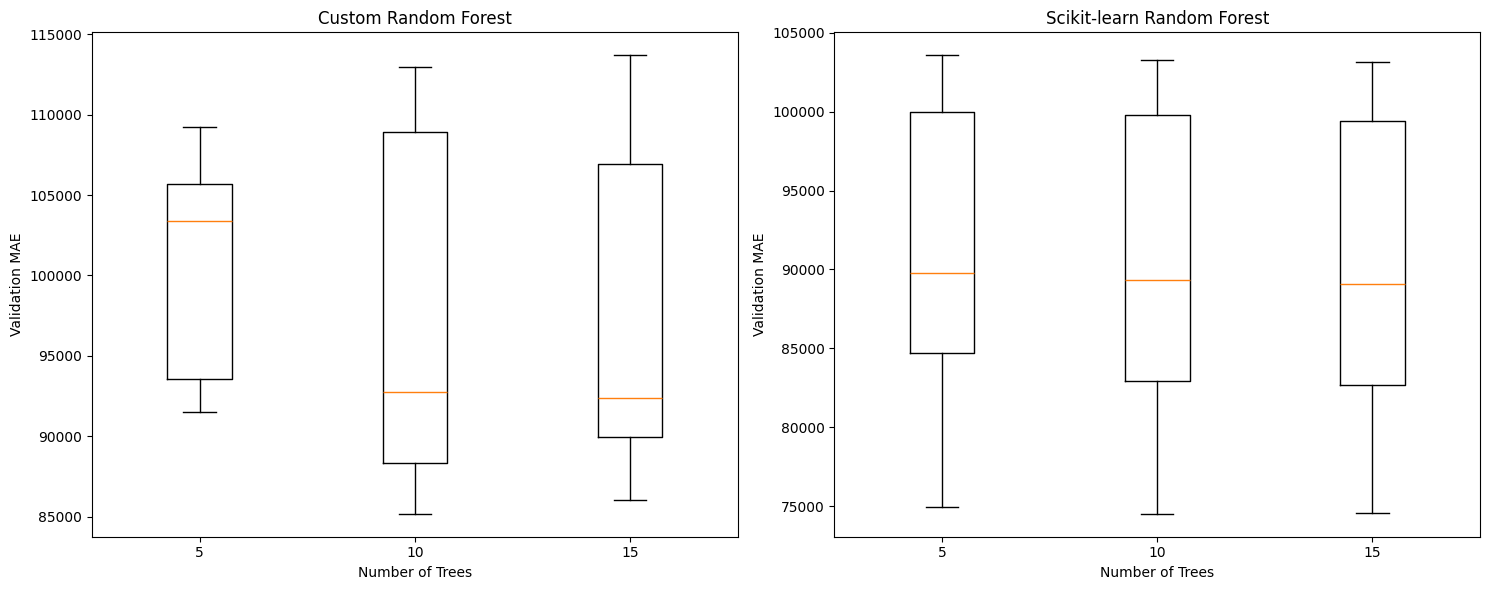

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, results, title in [
    (axes[0], custom_cv_df, "Custom Random Forest"),
    (axes[1], sklearn_cv_df, "Scikit-learn Random Forest")
]:
    data = [
        results[results["Trees"] == n]["Fold MAEs"].explode().astype(float)
        for n in tree_numbers
    ]

    ax.boxplot(data, tick_labels=[str(n) for n in tree_numbers])
    ax.set_title(title)
    ax.set_xlabel("Number of Trees")
    ax.set_ylabel("Validation MAE")

plt.tight_layout()
plt.savefig("random_forest_cv.png", dpi=200)
plt.show()

In [21]:
best_n = int(best_row["Trees"])
best_depth = int(best_row["Depth"])
best_leaf = int(best_row["Min Leaf"])

final_forest = RandomForest(
    n_trees=best_n,
    max_depth=best_depth,
    min_samples_leaf=best_leaf
)

final_forest.fit(X_cv, y_cv)

test_predictions = final_forest.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print("Test MSE:", mean_squared_error(y_test, test_predictions))

results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": test_predictions,
    "Absolute Error": np.abs(y_test - test_predictions)
})

display(results.head(10).round(2))

Test MAE: 90846.93012051497
Test MSE: 13199192236.488857


,Actual Price,Predicted Price,Absolute Error
0,560000,494726.43,65273.57
1,354000,498724.10,144724.10
2,613000,554087.65,58912.35
3,636000,562800.58,73199.42
4,229000,406700.78,177700.78
5,489000,449895.83,39104.17
6,729000,516926.17,212073.83
7,715000,549629.61,165370.39
8,773000,655435.26,117564.74
9,518000,541057.41,23057.41


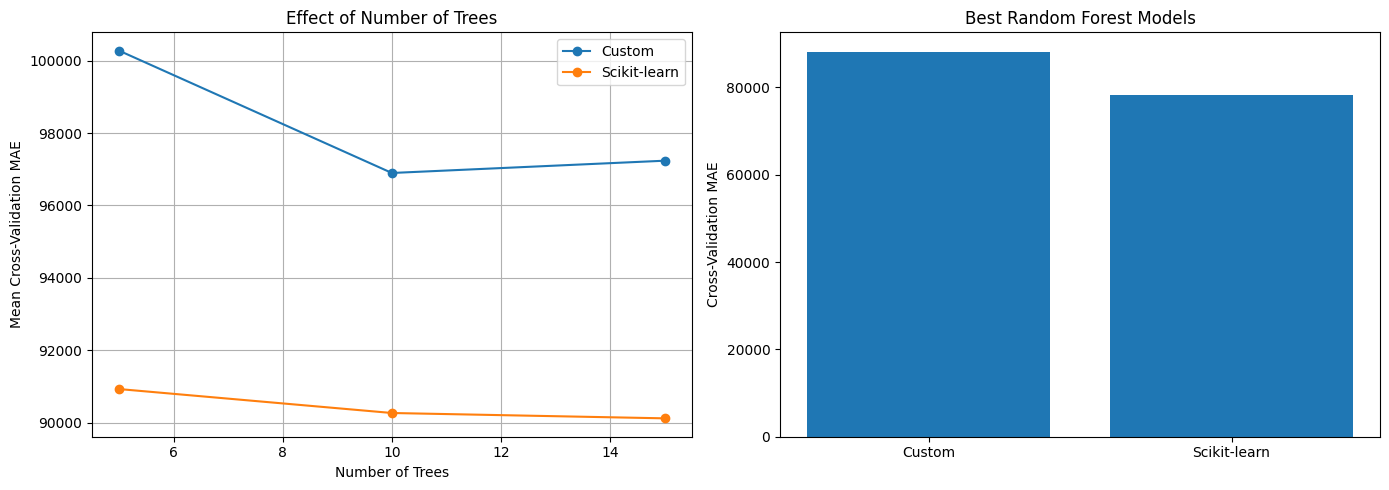

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for df_results, label in [
    (custom_cv_df, "Custom"),
    (sklearn_cv_df, "Scikit-learn")
]:
    means = df_results.groupby("Trees")["Mean MAE"].mean()

    axes[0].plot(
        means.index, means.values,
        marker="o", label=label
    )

axes[0].set_title("Effect of Number of Trees")
axes[0].set_xlabel("Number of Trees")
axes[0].set_ylabel("Mean Cross-Validation MAE")
axes[0].legend()
axes[0].grid(True)

# Compare best parameter combination for each model
custom_best = custom_cv_df.loc[
    custom_cv_df["Mean MAE"].idxmin()
]
sklearn_best = sklearn_cv_df.loc[
    sklearn_cv_df["Mean MAE"].idxmin()
]

axes[1].bar(
    ["Custom", "Scikit-learn"],
    [custom_best["Mean MAE"], sklearn_best["Mean MAE"]]
)

axes[1].set_title("Best Random Forest Models")
axes[1].set_ylabel("Cross-Validation MAE")

plt.tight_layout()
plt.savefig("forest_comparison.png", dpi=200)
plt.show()

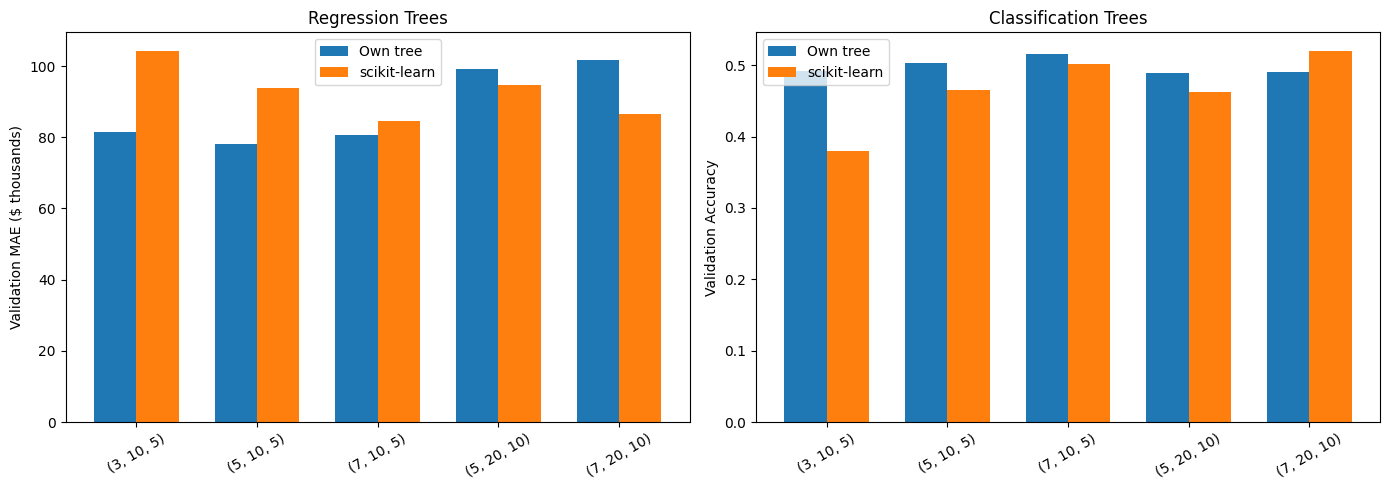

In [24]:
labels = [str(p) for p in parameters]
x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    x - width / 2,
    regression_df["Validation MAE"] / 1000,
    width, label="Own tree"
)
axes[0].bar(
    x + width / 2,
    sklearn_df["Validation MAE"] / 1000,
    width, label="scikit-learn"
)
axes[0].set_title("Regression Trees")
axes[0].set_ylabel("Validation MAE ($ thousands)")

axes[1].bar(
    x - width / 2,
    classification_df["Validation Accuracy"],
    width, label="Own tree"
)
axes[1].bar(
    x + width / 2,
    sklearn_class_df["Validation Accuracy"],
    width, label="scikit-learn"
)
axes[1].set_title("Classification Trees")
axes[1].set_ylabel("Validation Accuracy")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.legend()

plt.tight_layout()
plt.savefig("tree_comparison.png", dpi=200)
plt.show()

In [26]:
import pickle

# Recover medians from the original training rows
# before missing-value imputation
original_data = pd.read_csv(
    r"C:\Users\User\OneDrive - Kaunas University of Technology\Desktop\ML\LAB1\quebec_housing_sales_v2.csv"
).drop(columns=["property_id"], errors="ignore")

original_X = original_data.drop(columns=["sale_price"])

original_train, _ = train_test_split(
    original_X, test_size=0.30, random_state=42
)

medians = original_train[numeric_cols].median().to_dict()

saved_model = {
    "model": final_forest,
    "columns": X_train.columns.tolist(),
    "numeric_cols": numeric_cols.tolist(),
    "categorical_cols": categorical_cols.tolist(),
    "medians": medians
}

with open("final_forest.pkl", "wb") as f:
    pickle.dump(saved_model, f)

print("Model saved successfully!")

Model saved successfully!


In [27]:
def predict_record(record):
    with open("final_forest.pkl", "rb") as f:
        saved = pickle.load(f)

    row = {}

    for col in saved["columns"]:
        value = record.get(col)

        if pd.isna(value):
            if col in saved["numeric_cols"]:
                value = saved["medians"][col]
            else:
                value = "Unknown"

        row[col] = value

    X_new = pd.DataFrame([row], columns=saved["columns"])

    return saved["model"].predict(X_new)[0]


new_house = {
    "city": "Québec",
    "neighborhood": "Charlesbourg",
    "property_type": "Townhouse",
    "bedrooms": 3,
    "bathrooms": 2,
    "living_area_sqft": 1250,
    "lot_size_sqft": 3000,
    "year_built": 1995,
    "renovation_year": None,
    "garage": "Yes",
    "basement": "Yes",
    "sale_year": 2025
}

prediction = predict_record(new_house)
print(f"Predicted price: ${prediction:,.2f}")

Predicted price: $438,011.41
